# Empirical CDF (ECDF)

**Family:** Distribution &nbsp;|&nbsp; **Library:** matplotlib / seaborn &nbsp;|&nbsp; **Level:** Intermediate

> *Distribution:* Show values in a dataset and how often they occur; the shape (skew, spread, gaps) is the story.

## Design purpose

For every value x, plots the fraction of observations ≤ x. It has no bins or smoothing, and it answers percentile questions directly ('what share of users wait under 2 s?').

## When to use

- Compare distributions precisely, with no binning choices
- Read percentiles and thresholds (SLAs, latency, dose response)
- Overlay several groups without the clutter of overlapping histograms

## Avoid when

- The audience is unfamiliar with cumulative plots (shape is less intuitive than a histogram)

## Alternatives

- Histogram
- KDE density
- Box plot

## Design tips

- Add reference lines at key percentiles (median, p95)

## Example

Page-load latency for two server versions, 3,000 requests each, with p50 and p95 marked.

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio

PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
pio.templates["vizlib"] = go.layout.Template(layout=dict(
    colorway=PALETTE, font=dict(family="Helvetica, Arial, sans-serif", size=13, color="#0b0b0b"),
    paper_bgcolor="#fcfcfb", plot_bgcolor="#fcfcfb", title=dict(x=0.02, xanchor="left"),
    xaxis=dict(gridcolor="#e6e5e1", linecolor="#c9c8c3", zeroline=False),
    yaxis=dict(gridcolor="#e6e5e1", linecolor="#c9c8c3", zeroline=False),
))
pio.templates.default = "plotly_white+vizlib"
pio.renderers.default = "plotly_mimetype+notebook_connected"

### Data

In [2]:
rng = np.random.default_rng(29)
df = pd.concat([
    pd.DataFrame({"version": "v1", "latency_ms": rng.lognormal(5.6, 0.45, 3000)}),
    pd.DataFrame({"version": "v2", "latency_ms": rng.lognormal(5.35, 0.35, 3000)}),
], ignore_index=True)
df.groupby("version")["latency_ms"].quantile([0.5, 0.95]).unstack().round(0)

,0.50,0.95
version,,
v1,271.0,572.0
v2,208.0,376.0


### Plot

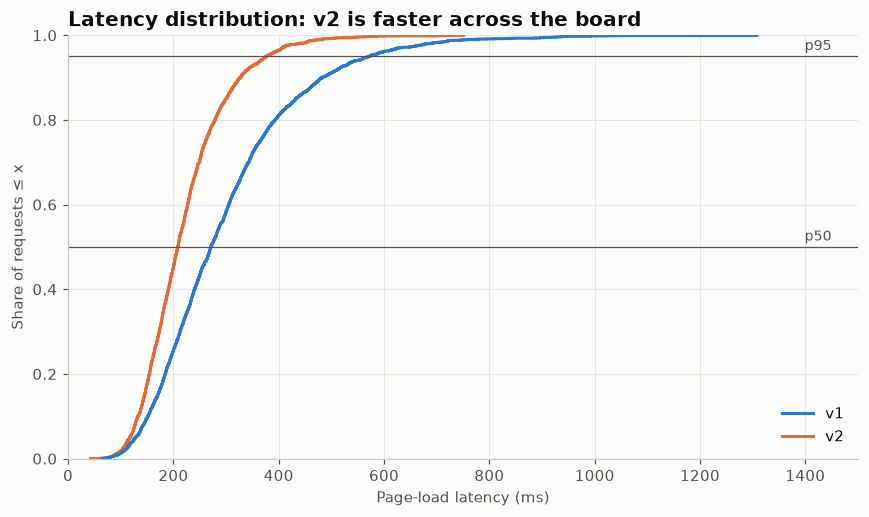

In [3]:
import seaborn as sns
fig, ax = plt.subplots(figsize=(8, 4.8))
sns.ecdfplot(data=df, x="latency_ms", hue="version", palette=PALETTE[:2], linewidth=2, ax=ax)
for q in [0.5, 0.95]:
    ax.axhline(q, color="#52514e", linewidth=0.8)
    ax.text(1450, q + 0.015, f"p{int(q * 100)}", fontsize=9, color="#52514e", ha="right")
ax.set_xlim(0, 1500)
ax.set_xlabel("Page-load latency (ms)")
ax.set_ylabel("Share of requests ≤ x")
ax.set_title("Latency distribution: v2 is faster across the board")
ax.get_legend().set_title(None)
fig.tight_layout()
plt.show()

## How to read it

Read across from p95 to each curve, then down: 95% of v2 requests finish faster than the v1 p95. A curve further left is better at every percentile.

## The same chart in other libraries

Each version uses the example data above. Pick the library that fits your stack: matplotlib/seaborn for static and print figures, plotly for interactive HTML, Altair for concise declarative specs.

### plotly

In [4]:
import plotly.express as px
fig = px.ecdf(df, x="latency_ms", color="version", color_discrete_sequence=PALETTE,
              labels={"latency_ms": "Page-load latency (ms)", "version": ""},
              title="Latency distribution: v2 is faster across the board")
for q in [0.5, 0.95]:
    fig.add_hline(y=q, line_color="#52514e", line_width=0.8, annotation_text=f"p{int(q * 100)}")
fig.update_layout(xaxis_range=[0, 1500], yaxis_title="Share of requests ≤ x")
fig.show()

---
Standalone script: [`ecdf.py`](ecdf.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)